# 07 · Feature importance, LinearSHAP and TreeSHAP, explained

A study guide for **section 6 of notebook 06** ("Feature importance beyond SHAP") and for the two SHAP
algorithms our models use. Every formula is followed by code that checks it on our own data, so
nothing has to be taken on trust.

**Contents**

1. What "feature importance" can mean: four different questions
2. The three importance measures in section 6, one by one
3. Partial dependence
4. Reading the section 6 results
5. Shapley values: the idea behind SHAP
6. LinearSHAP: SHAP for logistic regression
7. TreeSHAP: SHAP for tree models, checked against brute force
8. Common mistakes when interpreting importance

The notebook only reads saved results and fits two small toy models; it runs in about a minute.

In [1]:
import sys, itertools, math
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, "../src")
import paper134_models as M

R = Path("../results/models_v0.2")
X, y, cyc, names = M.load()
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 60)
print(X.shape, "| deaths:", int(y.sum()))

(9957, 134) | deaths: 1293


## 1. What "feature importance" can mean

"Which predictor is most important?" sounds like one question, but it is at least four:

| Question | Measure | Unit of the answer |
|---|---|---|
| How much does this predictor **move the predictions**? | SHAP (mean \|SHAP\|) | log-odds of death |
| How much **accuracy is lost** without the information in this predictor? | Permutation importance | drop in ROC-AUC |
| How much did the model **use** this predictor while training? | Built-in importance (gain, impurity, coefficient size) | model-specific |
| What is the **shape** of its effect? | Partial dependence | predicted risk |

They often agree on the very top predictors and disagree further down. Section 6 computes all of them
for all four models so the disagreements can be seen rather than assumed away.

## 2. The three importance measures

### 2a. SHAP importance

For each person $i$ and predictor $j$, SHAP gives a number $\phi_{ij}$: how much predictor $j$ pushed
that person's prediction up or down from the average prediction (sections 5–7 explain how). Global
importance is the average size of those pushes:

$$\text{SHAP importance}_j = \frac{1}{n}\sum_{i=1}^{n} |\phi_{ij}|$$

The absolute value matters: a predictor that pushes some people up a lot and others down a lot is
important even though its pushes cancel on average.

In our code (`src/paper134_analysis.py`): SHAP values for 300 held-out people per fold (1,500 in
total), one-hot columns summed back to the 134 original predictors.

### 2b. Permutation importance

Take the held-out data, shuffle one predictor's column so that it no longer matches the right people,
and measure how much ROC-AUC falls:

$$\text{Permutation importance}_j = \text{AUC}(\text{original}) - \text{AUC}(\text{predictor } j \text{ shuffled})$$

Shuffling keeps the predictor's distribution but destroys its link with the outcome. A predictor the
model does not use gives exactly zero. All one-hot columns of a categorical predictor are shuffled
together, so "Physical activity" is shuffled as one predictor. We use 3 shuffles per predictor per
fold and average.

The function, from our pipeline:

In [2]:
import inspect, paper134_analysis as A
print(inspect.getsource(A.permutation_importance))

def permutation_importance(model, Xte, yte, groups, feats, rng, repeats):
    """Drop in held-out ROC-AUC when one original predictor is shuffled
    (all one-hot columns of a categorical predictor move together)."""
    arr, g = Xte.to_numpy(copy=True), np.asarray(groups)
    base = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
    out = []
    for f in feats:
        idx = np.where(g == f)[0]
        saved, drops = arr[:, idx].copy(), []
        for _ in range(repeats):
            arr[:, idx] = saved[rng.permutation(len(arr))]
            p = model.predict_proba(pd.DataFrame(arr, columns=Xte.columns))[:, 1]
            drops.append(base - roc_auc_score(yte, p))
        arr[:, idx] = saved
        out.append(np.mean(drops))
    return np.asarray(out)



### 2c. Built-in importance

Each model type keeps its own bookkeeping:

| Model | Built-in measure | What it counts |
|---|---|---|
| XGBoost | total gain | total improvement in the loss from every split on this predictor |
| LightGBM | gain | the same idea |
| Random Forest | impurity decrease (Gini) | total reduction in node impurity from splits on this predictor |
| Logistic regression | \|standardized coefficient\| | how much the log-odds change per standard deviation |

It is computed on **training** data and costs nothing extra, but it measures use during training,
not usefulness on new people. Impurity importance is known to favour predictors with many distinct
values, such as continuous laboratory measures.

## 3. Partial dependence

Partial dependence shows the *shape* of an effect. Take a sample of people, set everyone's age to 50,
predict, and average; then set everyone to 51, and so on:

$$\text{PD}(a) = \frac{1}{n}\sum_{i=1}^{n} \hat f(x_i \text{ with age set to } a)$$

The curve answers "what would the model predict, on average, if age were $a$ and nothing else changed".
It can mislead when predictors are strongly correlated, because it creates people who do not exist
(an 85-year-old with a 40-year-old's troponin).

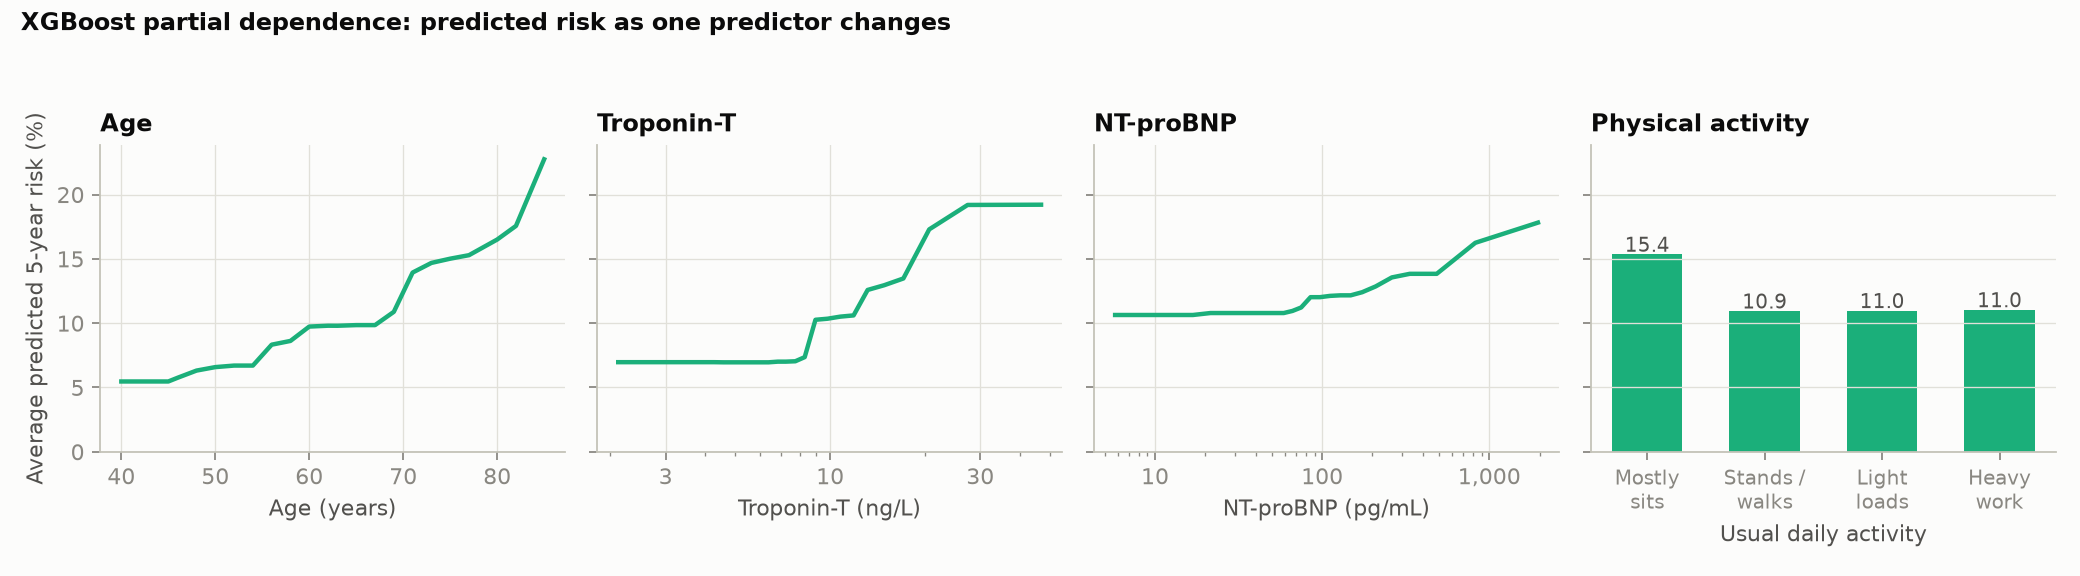

In [3]:
display(Image(filename=str(R / "fig_partial_dependence_xgboost.png"), width=1000))

## 4. Reading the section 6 results

### Do the three measures agree **within** one model?

Spearman correlation compares the full rankings of all 134 predictors (1 = identical order).
"Top-10 overlap" is the share of the ten most important predictors that two measures have in common.

In [4]:
within = pd.read_csv(R / "importance_agreement_between_measures.csv")
within.round(3)

,Model,Measure A,Measure B,Spearman of rankings,Top-10 overlap
0,Logistic Regression,SHAP,Permutation,0.877,0.9
1,Logistic Regression,SHAP,Built-in,0.927,0.8
2,Logistic Regression,Permutation,Built-in,0.891,0.8
3,Random Forest,SHAP,Permutation,0.316,0.8
4,Random Forest,SHAP,Built-in,0.917,0.9
5,Random Forest,Permutation,Built-in,0.213,0.7
6,XGBoost,SHAP,Permutation,0.554,0.8
7,XGBoost,SHAP,Built-in,0.979,0.8
8,XGBoost,Permutation,Built-in,0.513,0.8
9,LightGBM,SHAP,Permutation,0.632,0.8


How to read it:

- **SHAP and built-in importance agree closely** for every model, because both summarise how the
  model uses each predictor.
- **Permutation importance agrees less**, especially for Random Forest. Permutation measures how much
  accuracy is *lost*. When two predictors carry the same information (for example the thirty DNA
  methylation measures, or calf and thigh circumference), the model can use one heavily while losing
  almost nothing when it is shuffled, because its partner still carries the information.

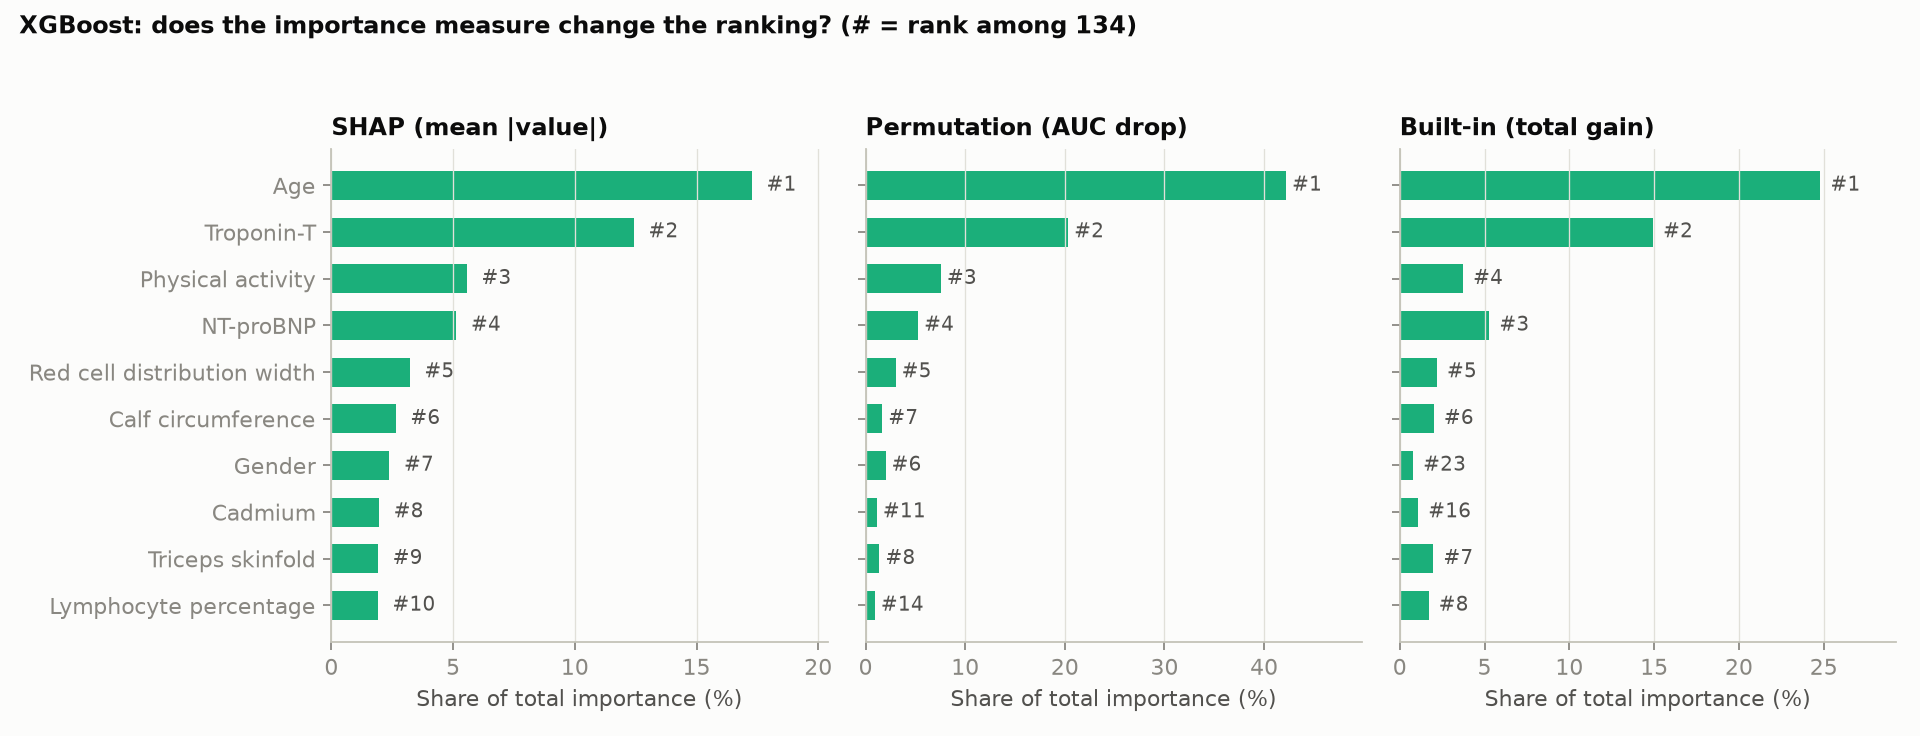

,#1,#2,#3,#4,#5
LR | SHAP,Age,Serum glucose,DNA methylation: NeuPP,Red blood cell count,Gender
LR | Permutation,Age,Serum glucose,Plasma glucose,DNA methylation: NeuPP,Physical activity
LR | Built-in,Age,Serum glucose,Income,Plasma glucose,Physical activity
RF | SHAP,Troponin-T,DNA methylation: GrimAge2Mort,DNA methylation: GrimAgeMort,Age,Physical activity
RF | Permutation,Troponin-T,Age,Physical activity,NT-proBNP,Cerebrovascular event history
RF | Built-in,Troponin-T,Age,DNA methylation: GrimAgeMort,DNA methylation: GrimAge2Mort,DNA methylation: TIMP1Mort
XGBoost | SHAP,Age,Troponin-T,Physical activity,NT-proBNP,Red cell distribution width
XGBoost | Permutation,Age,Troponin-T,Physical activity,NT-proBNP,Red cell distribution width
XGBoost | Built-in,Age,Troponin-T,NT-proBNP,Physical activity,Red cell distribution width
LightGBM | SHAP,Troponin-T,DNA methylation: GrimAge2Mort,Physical activity,NT-proBNP,Red cell distribution width


In [5]:
display(Image(filename=str(R / "fig_importance_measures_xgboost.png"), width=1100))
top = pd.read_csv(R / "importance_top5_by_measure.csv").T
top.columns = [f"#{i + 1}" for i in range(top.shape[1])]
top

### Do the four models agree **with each other** under the same measure?

This is the global version of the research question in notebook 06, section 5.

In [6]:
between = pd.read_csv(R / "importance_agreement_between_models.csv")
between.pivot_table(index=["Model A", "Model B"], columns="Measure",
                    values="Spearman of rankings", sort=False).round(2)

Measure                            SHAP  Permutation  Built-in
Model A             Model B                                   
Logistic Regression Random Forest  0.18         0.05      0.16
                    XGBoost        0.14         0.08      0.12
                    LightGBM       0.13         0.25      0.04
Random Forest       XGBoost        0.40         0.23      0.42
                    LightGBM       0.75         0.40      0.76
XGBoost             LightGBM       0.64         0.52      0.69

How to read it:

- **XGBoost and LightGBM agree strongly**: same kind of model, so similar importance under every measure.
- **Logistic regression agrees with none of the tree models** (correlations near zero or below). A
  linear model can only use a predictor in a straight line, so it relies on different predictors from
  models that can use thresholds and interactions.
- The disagreement appears **under every measure**, so it is not an artefact of SHAP. This is the
  strongest evidence for the research question: models with similar accuracy (AUC 0.85–0.87) can
  rely on quite different predictors.

## 5. Shapley values: the idea behind SHAP

SHAP borrows the **Shapley value** from game theory (Shapley, 1953): a fair way to split a team's
payout among its players.

Here the "players" are the predictors, and the "payout" is how far one person's prediction is from the
average prediction. Let $v(S)$ be the model's prediction for this person when it only knows the
predictors in the set $S$. The Shapley value of predictor $j$ is its extra contribution, averaged over
every possible order in which predictors could be revealed:

$$\phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(p-|S|-1)!}{p!}\,\big[v(S \cup \{j\}) - v(S)\big]$$

where $F$ is the set of all $p$ predictors. The weight is simply the share of orderings in which
exactly the predictors in $S$ come before $j$.

The Shapley value is the **only** way of splitting that satisfies these properties:

| Property | Meaning |
|---|---|
| Efficiency (local accuracy) | $\phi_0 + \sum_j \phi_j = f(x)$: baseline plus contributions equals the prediction exactly |
| Symmetry | two predictors that always contribute the same get the same value |
| Dummy (missingness) | a predictor that never changes anything gets 0 |
| Additivity | for a sum of models (a forest), the values add up |

The catch: there are $2^{p-1}$ subsets. With 134 predictors that is about $10^{40}$, far too many to
compute directly. **LinearSHAP and TreeSHAP are shortcuts that give the exact answer for particular
model types without enumerating subsets.** (KernelSHAP and PermutationSHAP, used in notebook 03,
are approximations that work for any model.)

### A two-predictor example by hand

Suppose for one person: knowing nothing, the model says 10%; knowing only age, 30%; only troponin,
20%; both, 50%.

In [7]:
v = {(): 10, ("age",): 30, ("tnt",): 20, ("age", "tnt"): 50}
def shapley(player, players=("age", "tnt")):
    others = [q for q in players if q != player]
    p = len(players); total = 0.0
    for r in range(len(others) + 1):
        for S in itertools.combinations(others, r):
            w = math.factorial(len(S)) * math.factorial(p - len(S) - 1) / math.factorial(p)
            with_j = tuple(sorted(S + (player,)))
            total += w * (v[with_j] - v[tuple(sorted(S))])
    return total
phi = {q: shapley(q) for q in ("age", "tnt")}
print(phi, "| baseline 10 +", sum(phi.values()), "=", 10 + sum(phi.values()), "(the full prediction, 50)")

{'age': 25.0, 'tnt': 15.0} | baseline 10 + 40.0 = 50.0 (the full prediction, 50)


Age gets 25 and troponin 15: age added 20 when it came first and 30 when it came second, so it gets the
average of the two orders.

## 6. LinearSHAP: SHAP for logistic regression

For a linear model $f(x) = \beta_0 + \sum_j \beta_j x_j$ (in log-odds), and treating predictors as
independent, the Shapley value has a closed form:

$$\phi_j = \beta_j\,(x_j - \mathbb{E}[x_j])$$

**Why.** Under independence, "the model only knows $S$" means the unknown predictors are replaced by
their average: $v(S) = \beta_0 + \sum_{k \in S} \beta_k x_k + \sum_{k \notin S} \beta_k \mathbb{E}[x_k]$.
Adding $j$ to any set changes $v$ by exactly $\beta_j (x_j - \mathbb{E}[x_j])$, whatever else is in
$S$. Every term in the Shapley sum is the same number, and the weights add up to 1.

**In words:** a predictor's contribution is its coefficient times how far this person is from the
average person. A 75-year-old gets a large positive age contribution; a 55-year-old (near the average)
gets almost none.

**In our pipeline** inputs are standardized, $z_j = (x_j - \bar x_j)/s_j$, so $\phi_j = \beta^{z}_j z_j$,
which is exactly what `LR.shap_values` computes. Check it against the formula and against the
`shap` library on a small logistic regression with five predictors:

In [8]:
import shap
from sklearn.linear_model import LogisticRegression

cols = ["RIDAGEYR", "SSTNT", "SSBNP", "LBXRDW", "BMXCALF"]
d = X[cols].dropna(); yy = y.loc[d.index]
lr = M.LR().fit(d.to_numpy(), yy)                  # the class used in our pipeline

ours = lr.shap_values(d.to_numpy())                # standardized x times coefficient
beta = lr.m.coef_[0] / lr.sc.scale_                # coefficients in original units
formula = beta * (d.to_numpy() - d.to_numpy().mean(axis=0))
# By default the library estimates "the average person" from only 100 sampled people, so its
# answer changes slightly with the sample. Give it everyone to compare like with like.
masker = shap.maskers.Independent(d.to_numpy(), max_samples=len(d))
lib = shap.LinearExplainer((beta, 0.0), masker).shap_values(d.to_numpy())

print("our code vs formula, largest difference:", np.abs(ours - formula).max())
print("formula vs shap library, largest difference:", np.abs(formula - lib).max())

logit = lr.m.decision_function(lr.sc.transform(d.to_numpy()))
base = logit.mean()
print("efficiency: baseline + sum of SHAP = model log-odds, largest error:",
      np.abs(base + ours.sum(axis=1) - logit).max())

our code vs formula, largest difference: 8.881784197001252e-16
formula vs shap library, largest difference: 0.0
efficiency: baseline + sum of SHAP = model log-odds, largest error: 1.7763568394002505e-15


In [9]:
person = d.index[np.argmax(logit)]          # the highest-risk person in this toy model
i = d.index.get_loc(person)
pd.DataFrame({"value": d.loc[person], "average": d.mean(), "coefficient (per unit)": beta,
              "SHAP = coef x (value - average)": ours[i]}).round(4)

,value,average,coefficient (per unit),SHAP = coef x (value - average)
RIDAGEYR,66.0,60.9581,0.0655,0.3303
SSTNT,417.1,10.6820,0.0239,9.7258
SSBNP,35000.0,270.8282,0.0001,3.6584
LBXRDW,27.6,12.9042,0.2259,3.3203
BMXCALF,28.5,37.9778,-0.0807,0.7650


**Limitations of LinearSHAP**

- It explains a *linear* model. If the true effect bends (troponin matters only above about 10 ng/L),
  the model and its explanation both miss that.
- The independence assumption: with correlated predictors (for example thigh and calf circumference),
  LinearSHAP credits each by its own coefficient. Logistic regression itself splits correlated
  predictors' weights somewhat arbitrarily, which is one reason it disagrees with the tree models.

## 7. TreeSHAP: SHAP for tree models, checked against brute force

A tree model has no single coefficient per predictor, so we need $v(S)$, "the prediction when only $S$
is known", for a tree.

**How a tree answers "what if we only know $S$?"** Walk down the tree from the root. At a split on a
predictor **in** $S$, follow this person's branch. At a split on a predictor **not in** $S$, go down
*both* branches and average them, weighted by how many training people went each way (the node's
"cover"). The weighted average of the leaves reached is $v(S)$.

**Brute force** computes $v(S)$ this way for all $2^p$ subsets and applies the Shapley formula.
**TreeSHAP** (Lundberg et al., 2020) gets the identical numbers by walking the tree once and tracking,
for every path, what fraction of all subsets reach each leaf. Its cost grows with tree size and depth
($O(T L D^2)$ for $T$ trees, $L$ leaves and depth $D$), not with $2^p$. That is why it can explain an
XGBoost model with 173 input columns for thousands of people in seconds.

Below we fit a small decision tree on six predictors, compute SHAP values by brute force (64 subsets
per person), and compare with the `shap` library's TreeSHAP.

In [10]:
from sklearn.tree import DecisionTreeRegressor

cols = ["RIDAGEYR", "SSTNT", "SSBNP", "LBXRDW", "BMXCALF", "LBXSAL"]
d = X[cols].dropna(); yy = y.loc[d.index].astype(float)
tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50, random_state=0).fit(d, yy)
t = tree.tree_

def v(x, S):
    # Expected tree output when only the predictors in S are known (path-dependent rule).
    def walk(node):
        if t.children_left[node] == -1:                        # leaf
            return t.value[node][0][0]
        j, left, right = t.feature[node], t.children_left[node], t.children_right[node]
        if j in S:                                             # known: follow this person's branch
            return walk(left if x[j] <= t.threshold[node] else right)
        wl, wr = t.weighted_n_node_samples[left], t.weighted_n_node_samples[right]
        return (wl * walk(left) + wr * walk(right)) / (wl + wr)  # unknown: average both branches
    return walk(0)

def brute_force_shap(x):
    p = len(x); phi = np.zeros(p)
    for j in range(p):
        others = [k for k in range(p) if k != j]
        for r in range(p):
            for S in itertools.combinations(others, r):
                w = math.factorial(r) * math.factorial(p - r - 1) / math.factorial(p)
                phi[j] += w * (v(x, set(S) | {j}) - v(x, set(S)))
    return phi

people = d.sample(200, random_state=1)
bf = np.array([brute_force_shap(x) for x in people.to_numpy()])
ts = shap.TreeExplainer(tree, feature_perturbation="tree_path_dependent").shap_values(people)
print("brute force vs TreeSHAP, largest difference over 200 people x 6 predictors:", np.abs(bf - ts).max())
print("baseline v(empty set):", round(v(people.to_numpy()[0], set()), 6),
      "| TreeExplainer expected value:", round(float(np.ravel(shap.TreeExplainer(tree).expected_value)[0]), 6))

brute force vs TreeSHAP, largest difference over 200 people x 6 predictors: 1.6653345369377348e-16
baseline v(empty set): 0.097782 | TreeExplainer expected value: 0.097782


In [11]:
x0 = people.iloc[0]
pd.DataFrame({"value": x0, "brute force SHAP": bf[0], "TreeSHAP": ts[0]}).round(5)

,value,brute force SHAP,TreeSHAP
RIDAGEYR,81.00,0.13607,0.13607
SSTNT,10.33,-0.05424,-0.05424
SSBNP,1544.00,0.13686,0.13686
LBXRDW,13.30,-0.00329,-0.00329
BMXCALF,30.50,0.03297,0.03297
LBXSAL,3.90,0.00000,0.00000


The two agree to rounding error: TreeSHAP is not an approximation.

**What our pipeline uses**

| Model | SHAP method | Output scale |
|---|---|---|
| XGBoost | TreeSHAP, computed by XGBoost itself (`pred_contribs=True`) | log-odds |
| LightGBM | TreeSHAP, computed by LightGBM itself (`pred_contrib=True`) | log-odds |
| Random Forest | TreeSHAP via `shap.TreeExplainer` | probability |
| Logistic regression | LinearSHAP (section 6 above) | log-odds |

Because Random Forest's values are on the probability scale and the others on log-odds, notebook 06
compares **rankings** across models, never raw SHAP sizes.

**SHAP interaction values** (used for the troponin × NT-proBNP check in notebook 06, section 7) split
each $\phi_j$ further into a main effect and pairwise interaction effects, using the same tree walk.

**Path-dependent vs interventional TreeSHAP.** The rule above ("average both branches by training
cover") is the *path-dependent* version: it follows how predictors were distributed in the training
data along each path. The *interventional* version instead replaces unknown predictors with values from
a background sample. They differ when predictors are correlated. XGBoost's and LightGBM's built-in
SHAP, and our Random Forest SHAP, are path-dependent.

## 8. Common mistakes when interpreting importance

1. **Importance is not causation.** High SHAP for cadmium means the model uses cadmium, perhaps as a
   marker of smoking, not that cadmium causes death.
2. **Correlated predictors share or steal credit.** Calf and thigh circumference correlate at 0.85;
   a model may credit either. Grouping correlated predictors (as notebook 06 does) gives fairer
   comparisons.
3. **Missing data changes explanations.** Filling in missing values changed XGBoost's top predictor for
   more than half of people (notebook 06, section 5).
4. **Different scales.** Compare rankings, not raw SHAP sizes, across model types.
5. **Global importance hides individuals.** A predictor can be unimportant on average yet decisive for
   a few people. Local SHAP values (notebook 06, section 5) show this.
6. **Permutation importance near zero does not mean "useless".** It can mean another predictor carries
   the same information.

**References**

- Lundberg & Lee (2017). A unified approach to interpreting model predictions. *NeurIPS* 30.
- Lundberg et al. (2020). From local explanations to global understanding with explainable AI for trees.
  *Nature Machine Intelligence* 2:56–67 (TreeSHAP).
- Shapley (1953). A value for n-person games. *Contributions to the Theory of Games* II.
- Breiman (2001). Random forests. *Machine Learning* 45:5–32 (permutation importance).
- Friedman (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*
  29:1189–1232 (partial dependence).